In [1]:
# %% Importación de paquetes ============================

# Trabajar con rutas relativas en python 
from pathlib import Path

# Módulos de numpy, pandas, matplotlib y scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss


In [3]:
df = pd.read_csv("despachocemento.csv")
df.head()

,periodo;Despacho nacional de cemento gris toneladas
0,1/4/2009;678.661
1,2/1/2009;695.755
2,3/1/2009;635.399
3,4/1/2009;741.963
4,5/1/2009;700.399


In [4]:
# primera serie despacho nacional de cemento gris

cemento_base = pd.read_csv(
    'despachocemento.csv',  
    sep=';',               
    header=None,            # Si el CSV no tiene encabezado en la primera fila
    names=['fecha', 'toneladas'] # Nombre para las dos columnas
)

# Ver el tipo de objeto de la base de datos (Pandas.DataFrame) y las primeras filas
print(type(cemento_base))
cemento_base.head()

<class 'pandas.DataFrame'>


,fecha,toneladas
0,periodo,Despacho nacional de cemento gris toneladas
1,1/4/2009,678.661
2,2/1/2009,695.755
3,3/1/2009,635.399
4,4/1/2009,741.963


In [5]:
# %% Creación del índice temporal de las series de tiempo

# Creación del índice temporal
fechas_cemento_base = pd.date_range(
    start="2009-04-01",
    periods=len(cemento_base),
    freq="MS"
)

# Agregar el índice temporal a la base de datos despachos nacionales de cemento gris
cemento_base.index = fechas_cemento_base

# El tipo de objeto de la base de datos sigue siendo Pandas.DataFrame
print(type(cemento_base))

# Ver primeras y últimas observaciones de la base de datos, ahora con índice temporal
print(cemento_base.head()) # Primeras observaciones
print(cemento_base.tail()) # Últimas observaciones 


<class 'pandas.DataFrame'>
               fecha                                    toneladas
2009-04-01   periodo  Despacho nacional de cemento gris toneladas
2009-05-01  1/4/2009                                      678.661
2009-06-01  2/1/2009                                      695.755
2009-07-01  3/1/2009                                      635.399
2009-08-01  4/1/2009                                      741.963
               fecha  toneladas
2026-05-01  1/1/2026  1.066.270
2026-06-01  2/1/2026  1.144.098
2026-07-01  3/1/2026  1.061.625
2026-08-01  4/1/2026  1.157.860
2026-09-01  5/1/2026  1.130.280


In [6]:
cemento_base = pd.read_csv(
    'despachocemento.csv',
    sep=';',
    skiprows=1,  # Salta las primeras 1 líneas de título/metadatos del DANE
    header=None, # O ponle 0 si la primera línea útil ya es el encabezado de columnas
    names=['fecha', 'toneladas']
)
# Ver primeras y últimas observaciones de la base de datos, ahora con índice temporal
print(cemento_base.head()) # Primeras observaciones
print(cemento_base.tail()) # Últimas observaciones 

      fecha toneladas
0  1/4/2009   678.661
1  2/1/2009   695.755
2  3/1/2009   635.399
3  4/1/2009   741.963
4  5/1/2009   700.399
        fecha  toneladas
204  1/1/2026  1.066.270
205  2/1/2026  1.144.098
206  3/1/2026  1.061.625
207  4/1/2026  1.157.860
208  5/1/2026  1.130.280


In [7]:
# %% Creación de la serie de tiempo de "despachos"

# La nueva serie de tiempo se va a llamar "cemento_serie" y va a tener valores numéricos
cemento_serie = cemento_base["toneladas"].copy()
cemento_serie = pd.to_numeric(cemento_serie, errors="coerce")
cemento_serie = cemento_serie.dropna() # Borrar missing values

# Ver el principio y final de la serie de tiempo
print(cemento_serie.head())
print(cemento_serie.tail())

# # El tipo de objeto de la base de datos ahora es un Pandas.Series
print(type(cemento_serie))

# Ver algunas estadísticas descriptivas de la serie de tiempo 
print(cemento_serie.describe())


0    678.661
1    695.755
2    635.399
3    741.963
4    700.399
Name: toneladas, dtype: float64
182    951.301
189    889.614
190    981.553
194    974.793
201    951.080
Name: toneladas, dtype: float64
<class 'pandas.Series'>
count    101.000000
mean     864.855653
std      117.963134
min      242.414000
25%      789.542000
50%      904.691000
75%      951.301000
max      999.412000
Name: toneladas, dtype: float64


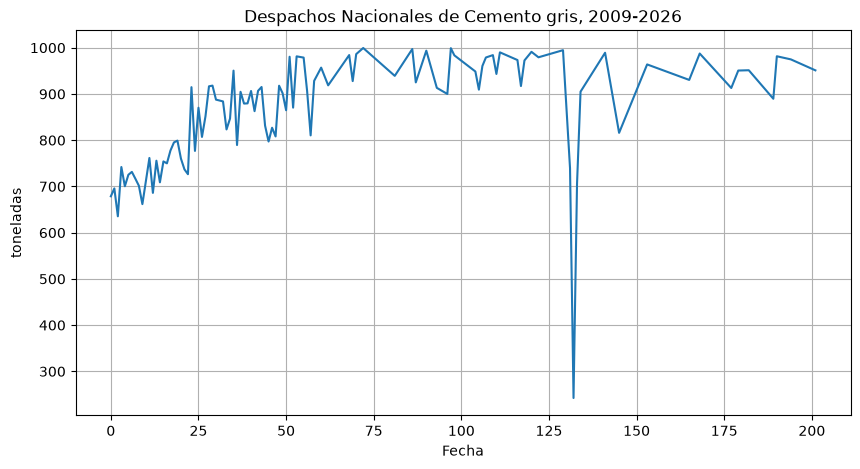

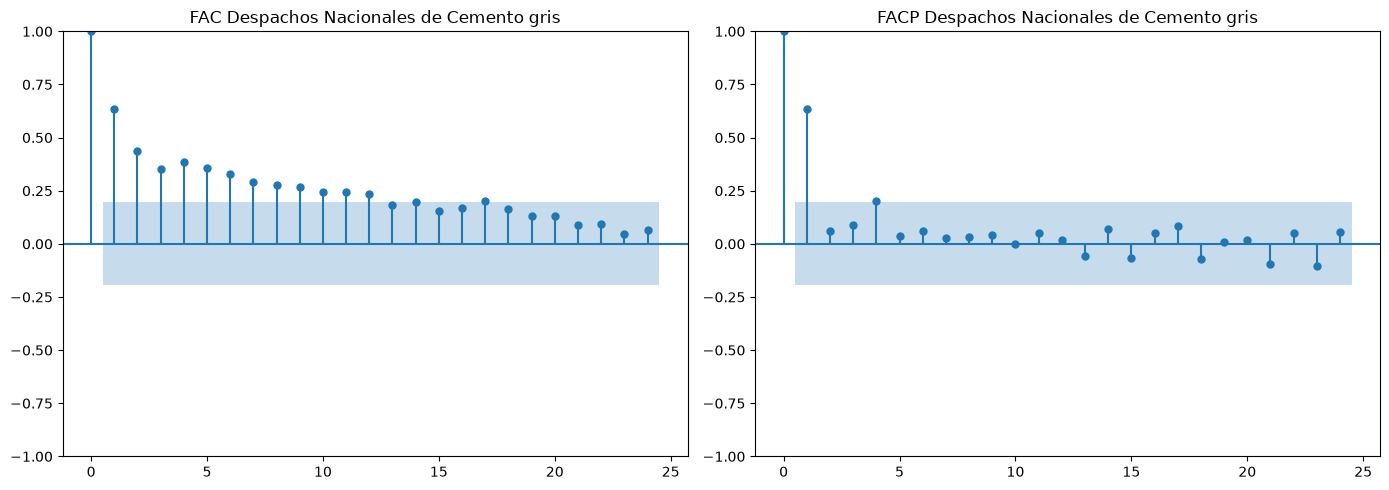

=== Test ADF ===
Estadístico ADF: -4.74533413780506
p-valor: 6.911146785835333e-05
Rezagos usados: 0
Observaciones: 100
Valores críticos:
1%: -3.497501033
5%: -2.89090644
10%: -2.5824349
ADF: Rechazamos H0. Según el test, la serie es estacionaria.

=== Test KPSS ===
Estadístico KPSS: 1.0463651772366753
p-valor: 0.01
Rezagos usados: 5
Valores críticos:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739
KPSS: rechazamos H0. Según el test, la serie es no estacionaria.


C:\Users\angel\AppData\Local\Temp\ipykernel_11056\2498753720.py:63: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(cemento_serie, regression="c", nlags="auto")


In [8]:

# %% =========================
# Paso 1: Identificación
# ============================

# Gráfica de la serie de tiempo "despachos nacionales de cemento gris"
plt.figure(figsize=(10, 5))
plt.plot(cemento_serie)
plt.title("Despachos Nacionales de Cemento gris, 2009-2026")
plt.xlabel("Fecha")
plt.ylabel("toneladas")
plt.grid(True)
plt.show()

# %% FAC y FACP de la serie original

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    cemento_serie,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC Despachos Nacionales de Cemento gris")

plot_pacf(
    cemento_serie,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP Despachos Nacionales de Cemento gris")

plt.tight_layout()
plt.show()

# %% Tests de Raíz Unitaria 

# Test de Augmented Dickey Fuller (ADF)
adf_result = adfuller(cemento_serie) # Test de Dickey Fuller sin intercepto y tendencia determínistica

# Nota: En el test de ADF si no rechazo la H0 la serie no es estacionaria
#       y si rechazo la H0 la serie es estacionaria. 

print("=== Test ADF ===")
print("Estadístico ADF:", adf_result[0])
print("p-valor:", adf_result[1])
print("Rezagos usados:", adf_result[2]) 
print("Observaciones:", adf_result[3])
print("Valores críticos:")
for nivel, valor in adf_result[4].items():
    print(f"{nivel}: {valor}")

if adf_result[1] < 0.05:
    print("ADF: Rechazamos H0. Según el test, la serie es estacionaria.")
else:
    print("ADF: No rechazamos H0. Según el test, la serie no es estacionaria.")

# Test KPSS
kpss_result = kpss(cemento_serie, regression="c", nlags="auto")

# Nota: En prueba KPSS se interpreta al contrario que una prueba ADF.
#       Si no rechazo la H0 la serie es estacionaria
#       y si rechazo la H0 la serie es no estacionaria. 

print("\n=== Test KPSS ===")
print("Estadístico KPSS:", kpss_result[0])
print("p-valor:", kpss_result[1])
print("Rezagos usados:", kpss_result[2])
print("Valores críticos:")
for nivel, valor in kpss_result[3].items():
    print(f"{nivel}: {valor}")

if kpss_result[1] < 0.05:
    print("KPSS: rechazamos H0. Según el test, la serie es no estacionaria.")
else:
    print("KPSS: no rechazamos H0. Según el test, La serie es estacionaria.")


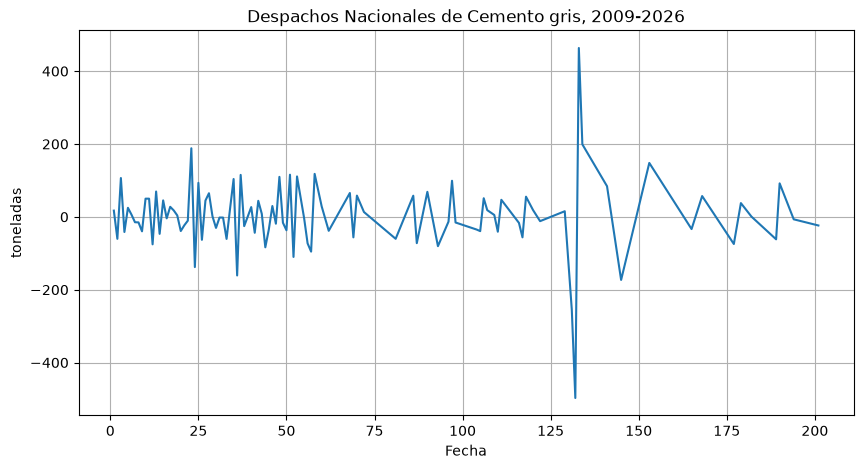

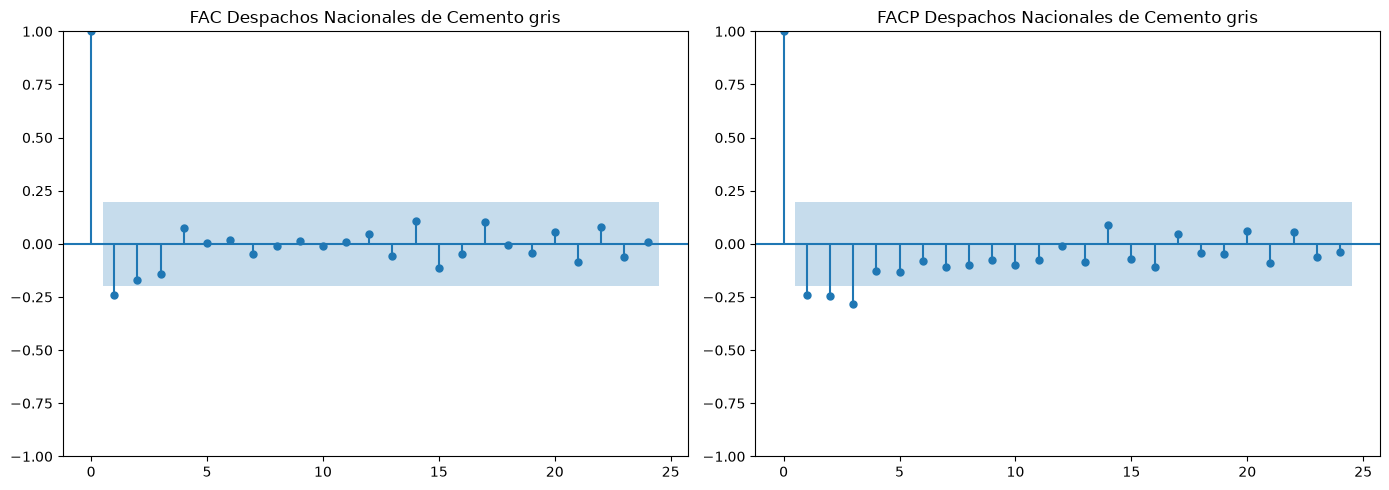

=== Test ADF ===
Estadístico ADF: -9.201766861276344
p-valor: 1.993223265960803e-15
Rezagos usados: 2
Observaciones: 97
Valores críticos:
1%: -3.4996365338407074
5%: -2.8918307730370025
10%: -2.5829283377617176
ADF: Rechazamos H0. Según el test, la serie es estacionaria.

=== Test KPSS ===
Estadístico KPSS: 0.12215327697850717
p-valor: 0.1
Rezagos usados: 18
Valores críticos:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739
KPSS: no rechazamos H0. Según el test, La serie es estacionaria.


C:\Users\angel\AppData\Local\Temp\ipykernel_11056\2314611775.py:64: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(cemento_serie_diff, regression="c", nlags="auto")


In [9]:
# Nota: Según los resultados de la prueba ADF y KPSS, hay que 
#       diferenciar la serie. 
# %% Serie diferenciada
cemento_serie_diff = cemento_serie.diff().dropna()

# Gráfica de la serie de tiempo "despachos nacionales de cemento gris diferenciado"
plt.figure(figsize=(10, 5))
plt.plot(cemento_serie_diff)
plt.title("Despachos Nacionales de Cemento gris, 2009-2026")
plt.xlabel("Fecha")
plt.ylabel("toneladas")
plt.grid(True)
plt.show()

# %% FAC y FACP de la serie con una diferencia

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    cemento_serie_diff,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC Despachos Nacionales de Cemento gris")

plot_pacf(
    cemento_serie_diff,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP Despachos Nacionales de Cemento gris")

plt.tight_layout()
plt.show()

# %% Tests de Raíz Unitaria 

# Test de Augmented Dickey Fuller (ADF)
adf_result = adfuller(cemento_serie_diff) # Test de Dickey Fuller sin intercepto y tendencia determínistica

# Nota: En el test de ADF si no rechazo la H0 la serie no es estacionaria
#       y si rechazo la H0 la serie es estacionaria. 

print("=== Test ADF ===")
print("Estadístico ADF:", adf_result[0])
print("p-valor:", adf_result[1])
print("Rezagos usados:", adf_result[2]) 
print("Observaciones:", adf_result[3])
print("Valores críticos:")
for nivel, valor in adf_result[4].items():
    print(f"{nivel}: {valor}")

if adf_result[1] < 0.05:
    print("ADF: Rechazamos H0. Según el test, la serie es estacionaria.")
else:
    print("ADF: No rechazamos H0. Según el test, la serie no es estacionaria.")

# Test KPSS
kpss_result = kpss(cemento_serie_diff, regression="c", nlags="auto")

# Nota: En prueba KPSS se interpreta al contrario que una prueba ADF.
#       Si no rechazo la H0 la serie es estacionaria
#       y si rechazo la H0 la serie es no estacionaria. 

print("\n=== Test KPSS ===")
print("Estadístico KPSS:", kpss_result[0])
print("p-valor:", kpss_result[1])
print("Rezagos usados:", kpss_result[2])
print("Valores críticos:")
for nivel, valor in kpss_result[3].items():
    print(f"{nivel}: {valor}")

if kpss_result[1] < 0.05:
    print("KPSS: rechazamos H0. Según el test, la serie es no estacionaria.")
else:
    print("KPSS: no rechazamos H0. Según el test, La serie es estacionaria.")


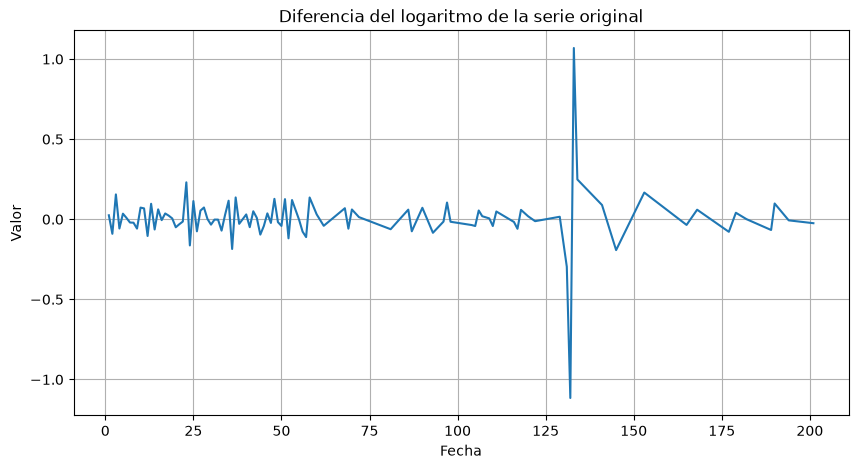

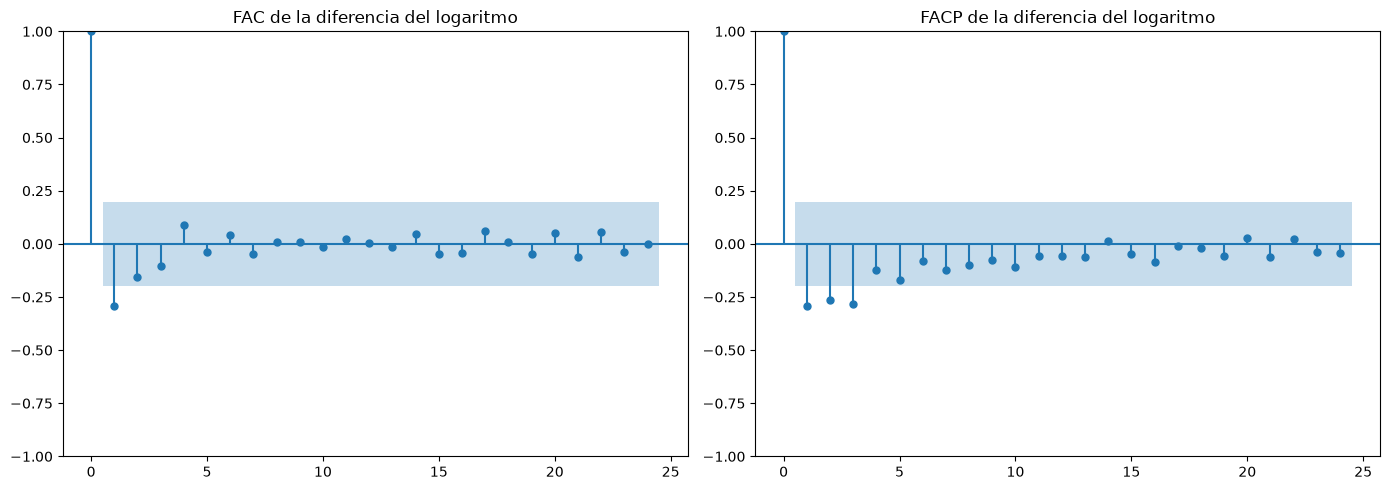

=== Test ADF ===
Estadístico ADF: -9.354470154025863
p-valor: 8.129225599327788e-16
Rezagos usados: 2
Observaciones: 97
Valores críticos:
1%: -3.4996365338407074
5%: -2.8918307730370025
10%: -2.5829283377617176
ADF: Rechazamos H0. Según el test, la serie es estacionaria.

=== Test KPSS ===
Estadístico KPSS: 0.15644054710513772
p-valor: 0.1
Rezagos usados: 27
Valores críticos:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739
KPSS: no rechazamos H0. Según el test, La serie es estacionaria.


C:\Users\angel\AppData\Local\Temp\ipykernel_11056\238141529.py:63: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(cemento_serie_log_diff, regression="c", nlags="auto")


In [10]:
# %% Diferencia del logaritmo

cemento_serie_log_diff = np.log(cemento_serie).diff().dropna()

# Gráfica de la serie de tiempo de la "diferencia del logaritmo de despachos de cemento gris"
plt.figure(figsize=(10, 5))
plt.plot(cemento_serie_log_diff)
plt.title("Diferencia del logaritmo de la serie original")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.grid(True)
plt.show()

# %% FAC y FACP de la diferencia del logaritmo

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    cemento_serie_log_diff,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC de la diferencia del logaritmo")

plot_pacf(
    cemento_serie_log_diff,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de la diferencia del logaritmo")

plt.tight_layout()
plt.show()

# %% Tests de Raíz Unitaria 

# Test de Augmented Dickey Fuller (ADF)
adf_result = adfuller(cemento_serie_log_diff) # Test de Dickey Fuller sin intercepto y tendencia determínistica

# Nota: En el test de ADF si no rechazo la H0 la serie no es estacionaria
#       y si rechazo la H0 la serie es estacionaria. 

print("=== Test ADF ===")
print("Estadístico ADF:", adf_result[0])
print("p-valor:", adf_result[1])
print("Rezagos usados:", adf_result[2]) 
print("Observaciones:", adf_result[3])
print("Valores críticos:")
for nivel, valor in adf_result[4].items():
    print(f"{nivel}: {valor}")

if adf_result[1] < 0.05:
    print("ADF: Rechazamos H0. Según el test, la serie es estacionaria.")
else:
    print("ADF: No rechazamos H0. Según el test, la serie no es estacionaria.")

# Test KPSS
kpss_result = kpss(cemento_serie_log_diff, regression="c", nlags="auto")

# Nota: En prueba KPSS se interpreta al contrario que una prueba ADF.
#       Si no rechazo la H0 la serie es estacionaria
#       y si rechazo la H0 la serie es no estacionaria. 

print("\n=== Test KPSS ===")
print("Estadístico KPSS:", kpss_result[0])
print("p-valor:", kpss_result[1])
print("Rezagos usados:", kpss_result[2])
print("Valores críticos:")
for nivel, valor in kpss_result[3].items():
    print(f"{nivel}: {valor}")

if kpss_result[1] < 0.05:
    print("KPSS: rechazamos H0. Según el test, la serie es no estacionaria.")
else:
    print("KPSS: no rechazamos H0. Según el test, La serie es estacionaria.")


In [12]:
# Paso 2: Estimación
# ============================

# Lo primero es crear un objeto de la clase SARIMAX 
# (Asociado a un MA(1) en éste ejemplo)
# Acá es donde se específica el modelo 
modelo_arima1 = SARIMAX(
    np.log(cemento_serie),
    order=(1, 1, 1),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Objeto tipo "SARIMAX" del paquete statmodels
type(modelo_arima1)

#  Acá es donde se realiza la estimación del modelo MA(1)
estimacion_arima1 = modelo_arima1.fit(disp=False)

# Nota: El método de estimación es máxima verosimilitud 
#       sobre la representación del modelo en un espacio de estados

# Objeto tipo "SARIMAXResultsWrapper"
type(estimacion_arima1)

# Se imprimen los resultados principales de la estimación
# E.g. Coeficientes y significancia de los coeficientes
print(estimacion_arima1.summary())



modelo_arima2 = SARIMAX(
    np.log(cemento_serie),
    order=(2, 1, 1),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Objeto tipo "SARIMAX" del paquete statmodels
type(modelo_arima2)

#  Acá es donde se realiza la estimación del modelo MA(1)
estimacion_arima2 = modelo_arima2.fit(disp=False)

# Nota: El método de estimación es máxima verosimilitud 
#       sobre la representación del modelo en un espacio de estados

# Objeto tipo "SARIMAXResultsWrapper"
type(estimacion_arima2)

# Se imprimen los resultados principales de la estimación
# E.g. Coeficientes y significancia de los coeficientes
print(estimacion_arima2.summary())

modelo_arima3 = SARIMAX(
    np.log(cemento_serie),
    order=(1, 1, 2),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Objeto tipo "SARIMAX" del paquete statmodels
type(modelo_arima3)

#  Acá es donde se realiza la estimación del modelo MA(1)
estimacion_arima3 = modelo_arima3.fit(disp=False)

# Nota: El método de estimación es máxima verosimilitud 
#       sobre la representación del modelo en un espacio de estados

# Objeto tipo "SARIMAXResultsWrapper"
type(estimacion_arima3)

# Se imprimen los resultados principales de la estimación
# E.g. Coeficientes y significancia de los coeficientes
print(estimacion_arima3.summary())

C:\Users\angel\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
C:\Users\angel\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
C:\Users\angel\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
C:\Users\angel\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, fore

                               SARIMAX Results                                
Dep. Variable:              toneladas   No. Observations:                  101
Model:               SARIMAX(1, 1, 1)   Log Likelihood                  45.982
Date:                Thu, 22 Oct 2026   AIC                            -85.964
Time:                        22:30:47   BIC                            -78.209
Sample:                             0   HQIC                           -82.828
                                - 101                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3137      0.108      2.912      0.004       0.103       0.525
ma.L1         -1.1049      0.108    -10.241      0.000      -1.316      -0.893
sigma2         0.0186      0.003      5.674      0.0

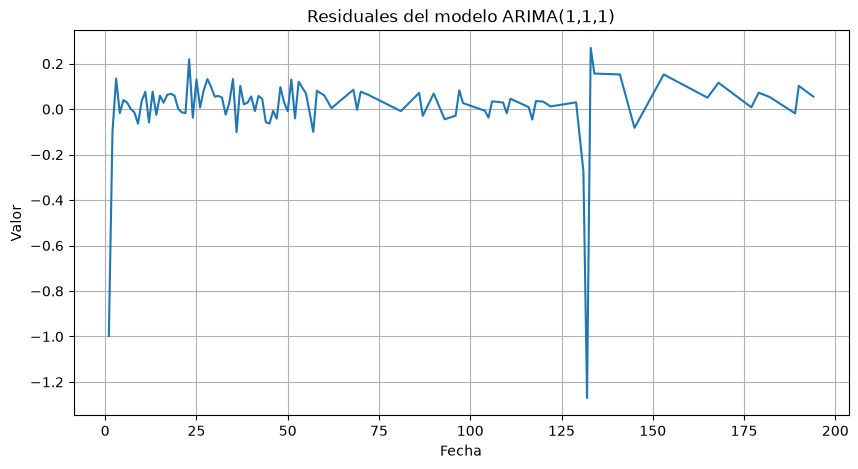

count    101.000000
mean       0.072925
std        0.672354
min       -1.270513
25%       -0.014403
50%        0.030100
75%        0.071529
max        6.520122
dtype: float64


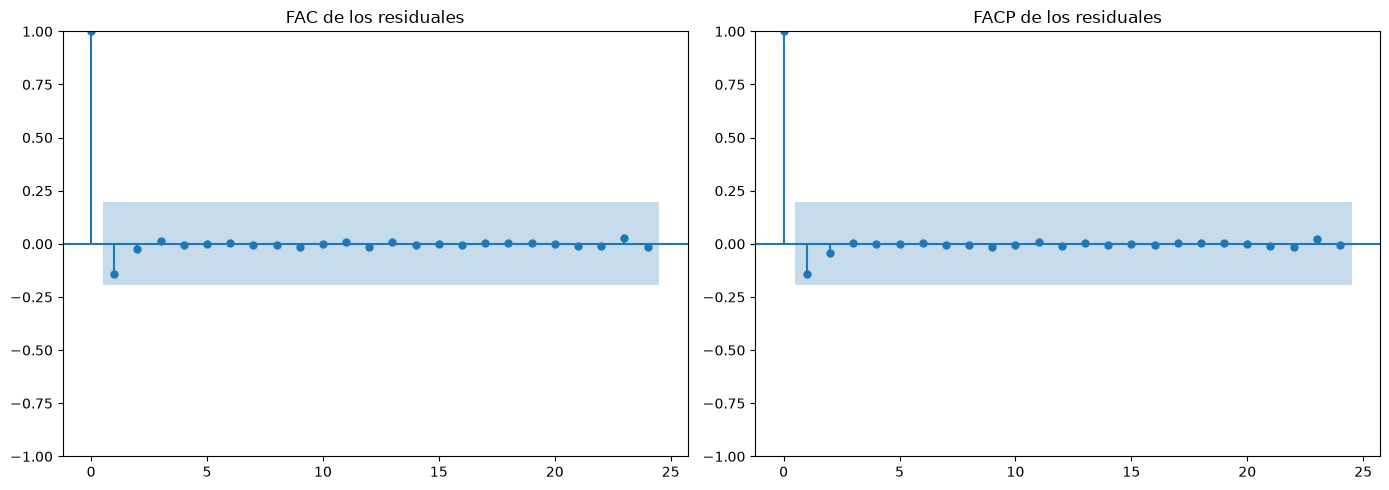

In [13]:
# %% =========================
# Paso 3: Validación de supuestos
# ============================

# Residuales del modelo
residuales = estimacion_arima1.resid.dropna()

# Los residuales son un objeto tipo Pandas.Series
type(residuales)

# Gráfica de los residuales (deberían comportarse como ruido blanco)
plt.figure(figsize=(10, 5))
plt.plot(residuales.iloc[1:-1])
plt.title("Residuales del modelo ARIMA(1,1,1)")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.grid(True)
plt.show()

# Descripción de los residuales 
print(residuales.describe())

# %% FAC y FACP de los residuales

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    residuales,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC de los residuales")

plot_pacf(
    residuales,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de los residuales")

plt.tight_layout()
plt.show()


Prueba Ljung-Box
     lb_stat  lb_pvalue
6   2.180681   0.902354
12  2.234148   0.998954
18  2.255554   0.999997
24  2.395114   1.000000


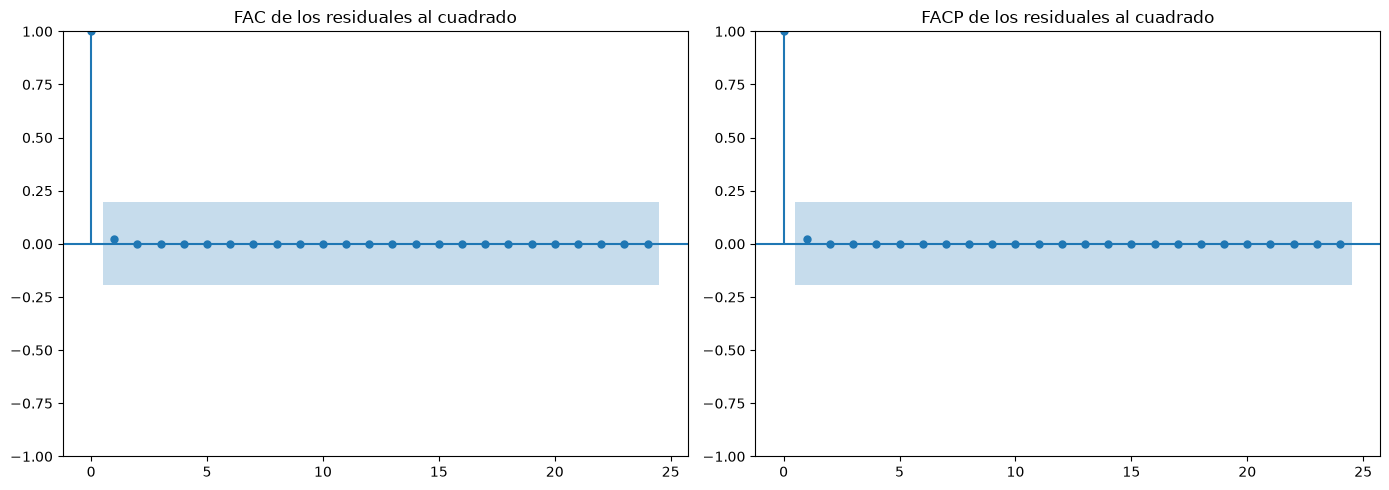

In [14]:
# %% Prueba Ljung-Box

ljung_box = acorr_ljungbox(
    residuales,
    lags=[6, 12, 18, 24],
    return_df=True
)

print("Prueba Ljung-Box")
print(ljung_box)

# H0: no hay autocorrelación en los residuos.
# Si p-value > 0.05, no se rechaza H0.

# %% FAC y FACP de los residuales al cuadrado

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    residuales**2,
    lags=24,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)

axes[0].set_title("FAC de los residuales al cuadrado")

plot_pacf(
    residuales**2,
    lags=24,
    alpha=0.05,
    ax=axes[1]
)

axes[1].set_title("FACP de los residuales al cuadrado")

plt.tight_layout()
plt.show()


Prueba ARCH
LM statistic: 0.6374965985536981
LM p-value: 0.9999988907143592


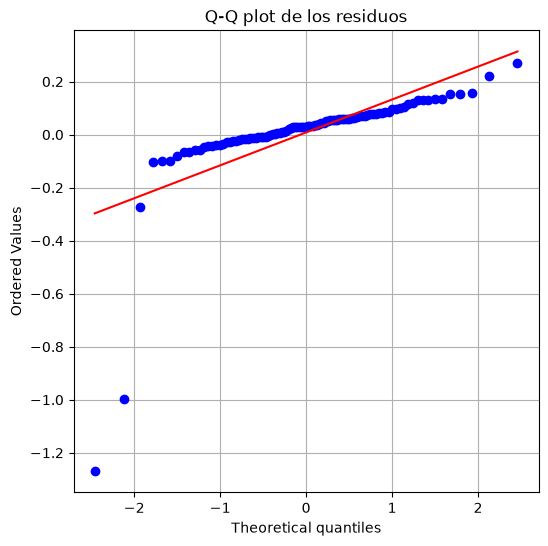

In [15]:
# %% Prueba ARCH de heterocedasticidad

arch_test = het_arch(residuales, nlags=12) 

print("Prueba ARCH")
print("LM statistic:", arch_test[0])
print("LM p-value:", arch_test[1])

# H0: no hay efectos ARCH.
# Si p-value > 0.05, no se rechaza H0.

# %% Q-Q plot de los residuos

plt.figure(figsize=(6, 6))
probplot(residuales.iloc[1:-1], dist="norm", plot=plt)
plt.title("Q-Q plot de los residuos")
plt.grid(True)
plt.show()


In [16]:
# %% Prueba de normalidad Jarque-Bera

jb_test = jarque_bera(residuales.iloc[1:-1])

print("Prueba Jarque-Bera")
print("Jarque-Bera statistic:", jb_test.statistic)
print("Jarque-Bera p-value:", jb_test.pvalue)

# H0: los residuos no siguen una distribución normal.
# Si p-value < 0.05, se rechaza H0.


Prueba Jarque-Bera
Jarque-Bera statistic: 4793.071598030339
Jarque-Bera p-value: 0.0


     pronostico  limite_inferior  limite_superior
101  931.287011       685.593146      1236.701171
102  923.627478       662.786456      1253.549301
103  921.210603       656.248749      1258.000496
104  920.574560       653.225224      1261.300910
105  920.510510       651.172220      1264.484761
106  920.627260       649.420020      1267.647203
107  920.800898       647.771287      1270.795284
108  920.992429       646.165388      1273.928910
109  921.189604       644.583295      1277.047943
110  921.388581       643.018859      1280.152505


C:\Users\angel\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\angel\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


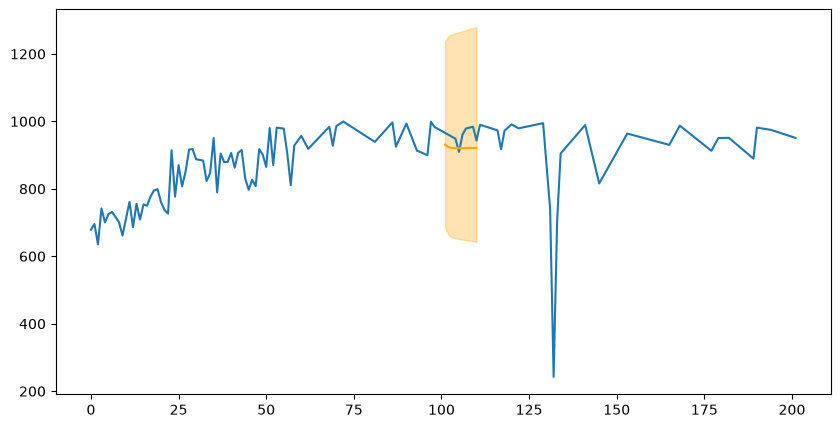

In [17]:
# PASO 4: Pronóstico
# ============================

# A partir de la estimación del MA(1) realizó el pronóstico

# Protonóstico 10 pasos adelante
pronostico_log = estimacion_arima1.get_forecast(steps=10)

# Pronóstico puntual e intervalos de predicción del logaritmo de las exportaciones tradicionales
pronostico_puntual_log = pronostico_log.predicted_mean
varianza_pronostico_log = pronostico_log.var_pred_mean
intervalos_log = pronostico_log.conf_int()

# Al retransformar desde logaritmos, exp(E[log(y)]) corresponde a la mediana.
# Para obtener la media en niveles se usa la corrección por sesgo:
# E[y] = exp(mu + 0.5 * sigma^2), bajo normalidad en la escala logarítmica.
pronostico_nivel = np.exp(pronostico_puntual_log + 0.5 * varianza_pronostico_log)
intervalos_nivel = np.exp(intervalos_log)

tabla_pronostico = pd.DataFrame({
    "pronostico": pronostico_nivel,
    "limite_inferior": intervalos_nivel.iloc[:, 0],
    "limite_superior": intervalos_nivel.iloc[:, 1]
})

print(tabla_pronostico)

# Gráfica del pronóstico
plt.figure(figsize=(10, 5))
plt.plot(cemento_serie, label="Datos históricos")
plt.plot(pronostico_nivel, label="Pronóstico", color="orange")
plt.fill_between(
    pronostico_nivel.index,
    intervalos_nivel.iloc[:, 0],
    intervalos_nivel.iloc[:, 1],
    color="orange",
    alpha=0.3,
    label="Intervalo de confianza"
)

# Note que para un MA(1), los pronósticos puntuales se vuelven 
# constantes después del primer paso adelante